In [1]:
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
from hashlib import sha256
from shutil import copyfileobj
from tempfile import NamedTemporaryFile
from itertools import combinations
import json

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
from scipy.signal import butter, sosfiltfilt
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'notebooks' / 'hitting').is_dir()), Path.cwd())
RAW = ROOT / 'data' / 'raw' / 'hitting'
OUT = ROOT / 'results' / 'hand_path_barrel_direction'
AUTO_DOWNLOAD = True
SAVE_OUTPUTS = True
PAIR_HITTER = None
SEED = 23
KEY = 'session_swing'
PROFILE = ['user', 'session', 'hitter_side']
POI_VECTOR = [f'sweet_spot_velo_mph_contact_{axis}' for axis in 'xyz']
IMPACT = ['poi_x', 'poi_y', 'poi_z']
LOCATION = ['horizontal_distance', 'vertical_distance']
COORDS = [f'{joint}_{axis}' for joint in ['lwjc', 'rwjc', 'left_hip', 'right_hip']
          for axis in 'xyz']
BASE = 'https://raw.githubusercontent.com/drivelineresearch/openbiomechanics/dataset-v1/baseball_hitting/data/'
ARCHIVE_URL = 'https://github.com/drivelineresearch/openbiomechanics/releases/download/dataset-v1/hitting_landmarks.zip'
ARCHIVE_SHA256 = '9cc2bdc94f5f5a6c5d540f4abe459caae2c5164cd53f6a6fd23f4b2b7283bcb3'
CSV_SOURCES = {
    'metadata.csv': 'metadata.csv',
    'poi_metrics.csv': 'poi/poi_metrics.csv',
    'hittrax.csv': 'poi/hittrax.csv',
}

def file_hash(path):
    with path.open('rb') as handle:
        digest = sha256()
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

def copy_atomic(source, target, expected_hash=None):
    with NamedTemporaryFile(dir=target.parent, delete=False) as handle:
        temp = Path(handle.name)
    try:
        with temp.open('wb') as handle:
            copyfileobj(source, handle)
        if expected_hash and file_hash(temp) != expected_hash:
            raise ValueError(f'SHA-256 mismatch for {target.name}')
        temp.replace(target)
    finally:
        temp.unlink(missing_ok=True)

def download(url, target, expected_hash=None):
    try:
        with urlopen(url, timeout=120) as source:
            copy_atomic(source, target, expected_hash)
    except OSError as error:
        raise RuntimeError(f'Could not download {target.name}. Place the Dataset v1 file in {RAW}.') from error

RAW.mkdir(parents=True, exist_ok=True)
for filename, suffix in CSV_SOURCES.items():
    path = RAW / filename
    if not path.exists() and AUTO_DOWNLOAD:
        download(BASE + suffix, path)

landmark_path = RAW / 'landmarks.csv'
if not landmark_path.exists():
    archive_path = RAW / 'hitting_landmarks.zip'
    if not archive_path.exists() and AUTO_DOWNLOAD:
        download(ARCHIVE_URL, archive_path, ARCHIVE_SHA256)
    if not archive_path.exists():
        raise FileNotFoundError(f'Place landmarks.csv or hitting_landmarks.zip in {RAW}.')
    if file_hash(archive_path) != ARCHIVE_SHA256:
        raise ValueError('hitting_landmarks.zip does not match the official Dataset v1 SHA-256.')
    with ZipFile(archive_path) as archive, archive.open('landmarks.csv') as source:
        copy_atomic(source, landmark_path)

def read_swings(filename, columns, strings=()):
    frame = pd.read_csv(RAW / filename, usecols=[KEY, *columns],
                        dtype={col: str for col in [KEY, *strings]})
    if frame[KEY].isna().any() or frame[KEY].duplicated().any():
        raise ValueError(f'Missing or duplicate swing keys in {filename}.')
    return frame

metadata = read_swings('metadata.csv', PROFILE, PROFILE)
poi = read_swings('poi_metrics.csv', ['attack_angle_contact_x', *POI_VECTOR])
hittrax = read_swings('hittrax.csv', [*IMPACT, *LOCATION])
landmarks = pd.read_csv(landmark_path, usecols=[KEY, 'time', 'contact_time', *COORDS],
                        dtype={KEY: str})
if metadata[PROFILE].isna().any().any():
    raise ValueError('Missing hitter, session, or side in metadata.')
if landmarks[KEY].isna().any() or landmarks.duplicated([KEY, 'time']).any():
    raise ValueError('Missing landmark swing keys or duplicate swing/time pairs.')
print(f'{len(metadata)} metadata swings | {landmarks[KEY].nunique()} landmark swings')


677 metadata swings | 677 landmark swings


In [2]:
CONFIGS = {
    'primary': (100, 12),
    'early_75ms': (75, 12),
    'early_125ms': (125, 12),
    'filter_8hz': (100, 8),
    'filter_16hz': (100, 16),
    'no_extra_filter': (100, None),
}
EARLY = ['early_depth_cm', 'max_drop_cm']
LATE = ['wrist_vx', 'wrist_vy', 'wrist_vz']

def sample_path(time, xyz, query):
    return np.column_stack([np.interp(query, time, col) for col in xyz.T])

def prepare_wrist(group, side):
    if side not in {'R', 'L'}:
        raise ValueError('invalid batting side')
    time = group.time.to_numpy(float)
    events = group.contact_time.to_numpy(float)
    if not np.isfinite(events).all() or np.ptp(events) > 1e-7:
        raise ValueError('missing or inconsistent contact time')
    contact = events[0]
    dt = np.diff(time)
    if (len(dt) < 29 or not np.isfinite(time).all() or np.any(dt <= 0)
            or not np.allclose(dt, np.median(dt), rtol=.03, atol=.00011)):
        raise ValueError('invalid or gapped time grid')
    if not time[0] <= contact <= time[-1]:
        raise ValueError('contact outside recording')
    end = np.searchsorted(time, contact, side='left') + 1
    prefix = 'lwjc' if side == 'R' else 'rwjc'
    wrist = group[[f'{prefix}_{a}' for a in 'xyz']].to_numpy(float)[:end]
    hips = (group[[f'left_hip_{a}' for a in 'xyz']].to_numpy(float)[:end]
            + group[[f'right_hip_{a}' for a in 'xyz']].to_numpy(float)[:end]) / 2
    if not np.isfinite(wrist).all() or not np.isfinite(hips).all():
        raise ValueError('nonfinite precontact wrist or hip coordinates')
    if not .3 < np.median(hips[:, 2]) < 1.6:
        raise ValueError('hip height inconsistent with metres')
    grid = np.linspace(time[0], contact, round((contact - time[0]) / np.median(dt)) + 1)
    if len(grid) < 30:
        raise ValueError('insufficient precontact samples')
    signs = np.array([1, 1 if side == 'R' else -1, 1])
    return (grid - contact, sample_path(time[:end], wrist, grid) * signs,
            sample_path(time[:end], hips, grid) * signs)

def path_features(time, wrist, hips, early_ms):
    start = -early_ms / 1000
    if time[0] > start + 1e-9:
        raise ValueError('incomplete early window')
    window = np.r_[start, time[(time > start) & (time < 0)], 0.]
    relative = sample_path(time, wrist - hips, window)
    lowest = np.argmin(relative[:, 2])
    late = np.linspace(-.020, 0, 9)
    centered = late - late.mean()
    v = centered @ sample_path(time, wrist, late) / (centered @ centered)
    speed = np.linalg.norm(v)
    if speed < .1 or np.hypot(v[0], v[1]) < .1:
        raise ValueError('low fitted wrist velocity')
    return {
        'early_depth_cm': 100 * relative[0, 0],
        'max_drop_cm': 100 * (relative[0, 2] - relative[lowest, 2]),
        'lowest_relative_z_ms': 1000 * window[lowest],
        'wrist_elevation_deg': np.degrees(np.arctan2(v[2], np.hypot(v[0], v[1]))),
        'wrist_azimuth_deg': np.degrees(np.arctan2(v[1], v[0])),
        **dict(zip(LATE, v / speed)),
    }

measurements, audit, traces = [], [], {}
identity = metadata.set_index(KEY)
for swing, group in landmarks.groupby(KEY, sort=False):
    if swing not in identity.index:
        audit.append({KEY: swing, 'configuration': 'all', 'status': 'no metadata'})
        continue
    try:
        t, wrist, hips = prepare_wrist(group.sort_values('time'), identity.at[swing, 'hitter_side'])
    except ValueError as error:
        audit.append({KEY: swing, 'configuration': 'all', 'status': str(error)})
        continue
    filtered = {None: (wrist, hips)}
    for config, (early_ms, hz) in CONFIGS.items():
        if hz not in filtered:
            sos = butter(4, hz, fs=1 / np.median(np.diff(t)), output='sos')
            filtered[hz] = (sosfiltfilt(sos, wrist, axis=0), sosfiltfilt(sos, hips, axis=0))
        w, h = filtered[hz]
        try:
            row = path_features(t, w, h, early_ms)
        except ValueError as error:
            audit.append({KEY: swing, 'configuration': config, 'status': str(error)})
            continue
        measurements.append({KEY: swing, 'configuration': config, **row})
        audit.append({KEY: swing, 'configuration': config, 'status': 'retained'})
        if config == 'primary':
            trace_t = np.linspace(-.100, 0, 101)
            traces[swing] = (trace_t, sample_path(t, w, trace_t), sample_path(t, h, trace_t))
for swing in sorted(set(identity.index) - set(landmarks[KEY])):
    audit.append({KEY: swing, 'configuration': 'all', 'status': 'no landmarks'})
if not measurements:
    raise ValueError('No usable wrist trajectories. Inspect landmark times and coordinates.')
wrist_features = pd.DataFrame(measurements)
eligibility = pd.DataFrame(audit)
print(eligibility.groupby(['configuration', 'status']).size().to_string())


configuration    status  
early_125ms      retained    677
early_75ms       retained    677
filter_16hz      retained    677
filter_8hz       retained    677
no_extra_filter  retained    677
primary          retained    677


In [3]:
vx, vy, vz = poi[POI_VECTOR].to_numpy(float).T
horizontal_speed = np.hypot(vx, vy)
valid_vector = np.isfinite(poi[POI_VECTOR]).all(axis=1) & (horizontal_speed > 0)
poi['attack_direction_deg'] = np.where(valid_vector, np.degrees(np.arctan2(vy, vx)), np.nan)
poi['vector_elevation_deg'] = np.where(
    valid_vector, np.degrees(np.arctan2(vz, horizontal_speed)), np.nan)
poi = poi.rename(columns={'attack_angle_contact_x': 'attack_angle_deg'})
difference = (poi.attack_angle_deg - poi.vector_elevation_deg).abs().dropna()
if not difference.empty:
    print(f'Published attack angle vs vector-derived elevation | median absolute difference '
          f'{difference.median():.2f}° | maximum {difference.max():.2f}° | n={len(difference)}')

hittrax['impact_status'] = np.select(
    [hittrax[IMPACT].eq(0).all(axis=1), ~np.isfinite(hittrax[IMPACT]).all(axis=1)],
    ['zero impact triple', 'nonfinite impact'], default='valid')
hittrax = hittrax.rename(columns={'poi_z': 'impact_depth', 'poi_y': 'impact_height'})
swings = (metadata.merge(poi, on=KEY, how='left', validate='one_to_one')
          .merge(hittrax, on=KEY, how='left', validate='one_to_one'))
swings['impact_status'] = swings.impact_status.fillna('no HitTrax row')
swings['reported_inside'] = swings.horizontal_distance * swings.hitter_side.map({'R': 1, 'L': -1})
primary = swings.merge(wrist_features.query("configuration == 'primary'").drop(columns='configuration'),
                       on=KEY, how='inner', validate='one_to_one')
CONTEXT = ['impact_depth', 'impact_height']
TARGETS = ['attack_angle_deg', 'attack_direction_deg']
usable_context = primary.impact_status.eq('valid')
print(f'Primary wrist cohort: {len(primary)} swings from {primary.user.nunique()} hitters')
print(primary.impact_status.value_counts().to_string())
for target in TARGETS:
    valid = np.isfinite(primary[target])
    print(f'{target}: {valid.sum()} labeled | {(valid & usable_context).sum()} with valid impact')
paired_context = primary.loc[usable_context].dropna(subset=['reported_inside', 'vertical_distance'])
coupling_cols = ['reported_inside', 'vertical_distance', 'impact_height', 'impact_depth']
centered = paired_context[coupling_cols] - paired_context.groupby(PROFILE)[coupling_cols].transform('mean')
print('\nWithin-profile correlations between reported location and impact coordinates')
print(centered.corr().loc[['reported_inside', 'vertical_distance'],
                           ['impact_height', 'impact_depth']].round(3).to_string())


Published attack angle vs vector-derived elevation | median absolute difference 0.11° | maximum 1.65° | n=677
Primary wrist cohort: 677 swings from 98 hitters
impact_status
valid                 515
zero impact triple     89
no HitTrax row         73
attack_angle_deg: 677 labeled | 515 with valid impact
attack_direction_deg: 677 labeled | 515 with valid impact

Within-profile correlations between reported location and impact coordinates
                   impact_height  impact_depth
reported_inside            0.005         0.255
vertical_distance          0.978        -0.009


In [4]:
RIDGE_ALPHA = 10.0
N_FOLDS = 5
N_BOOTSTRAPS = 2000
MODELS = {
    'cohort_mean': [],
    'late_wrist': LATE,
    'wrist_full': [*LATE, *EARLY],
}
CONTEXT_MODELS = {
    'impact_only': CONTEXT,
    'impact_plus_wrist': [*CONTEXT, *LATE, *EARLY],
}
if primary.user.nunique() < N_FOLDS:
    raise ValueError(f'At least {N_FOLDS} hitters are required for grouped evaluation.')
fold_map = {}
for fold, (_, test_idx) in enumerate(GroupKFold(N_FOLDS).split(primary, groups=primary.user), 1):
    fold_map.update(dict.fromkeys(primary.iloc[test_idx].user.unique(), fold))

def signed_error(predicted, actual, circular):
    delta = np.asarray(predicted) - np.asarray(actual)
    return (delta + 180) % 360 - 180 if circular else delta

def evaluate(cohort, target, models, label):
    columns = sorted({col for features in models.values() for col in features})
    sample = cohort.replace([np.inf, -np.inf], np.nan).dropna(subset=[target, *columns]).copy()
    sample['fold'] = sample.user.map(fold_map)
    if sample.fold.nunique() < 2:
        return pd.DataFrame()
    circular = target == 'attack_direction_deg'
    results = []
    for fold in sorted(sample.fold.unique()):
        train, test = sample.loc[sample.fold.ne(fold)], sample.loc[sample.fold.eq(fold)]
        assert set(train.user).isdisjoint(test.user)
        y = train[target].to_numpy()
        if circular:
            y_rad = np.deg2rad(y)
            y = np.column_stack([np.cos(y_rad), np.sin(y_rad)])
        for model, features in models.items():
            if features:
                fit = make_pipeline(StandardScaler(), Ridge(alpha=RIDGE_ALPHA))
                fit.fit(train[features], y)
                estimate = fit.predict(test[features])
            else:
                estimate = np.repeat(np.mean(y, axis=0)[None, ...], len(test), axis=0)
            if circular:
                estimate = np.degrees(np.arctan2(estimate[:, 1], estimate[:, 0]))
            result = test[[KEY, *PROFILE, 'fold', target]].rename(columns={target: 'actual_deg'}).copy()
            result['prediction_deg'] = estimate
            result['error_deg'] = signed_error(estimate, result.actual_deg, circular)
            result['cohort'], result['target'], result['model'] = label, target, model
            results.append(result)
    return pd.concat(results, ignore_index=True)

blocks = []
for target in TARGETS:
    blocks.append(evaluate(primary, target, MODELS, 'wrist cohort'))
    blocks.append(evaluate(primary.loc[usable_context], target,
                           {**MODELS, **CONTEXT_MODELS}, 'matched impact cohort'))
predictions = pd.concat(blocks, ignore_index=True)
assert not predictions.duplicated(['cohort', 'target', 'model', KEY]).any()

def summarize(preds):
    rows = []
    for labels, group in preds.groupby(['cohort', 'target', 'model'], sort=False):
        error = group.error_deg
        hitter = group.assign(ae=error.abs(), se=error**2).groupby('user')[['ae', 'se']].mean()
        directional = group.loc[group.actual_deg.ne(0)].copy()
        directional['correct'] = (np.sign(directional.prediction_deg)
                                  == np.sign(directional.actual_deg))
        by_sign = (directional.assign(sign=np.sign(directional.actual_deg))
                   .groupby(['sign', 'user']).correct.mean().groupby('sign').mean())
        rows.append((*labels, len(group), len(hitter), hitter.ae.mean(),
                     np.sqrt(hitter.se.mean()), by_sign.get(-1, np.nan),
                     by_sign.get(1, np.nan), by_sign.mean() if len(by_sign) == 2 else np.nan))
    return pd.DataFrame(rows, columns=['cohort', 'target', 'model', 'swings', 'hitters',
                                      'mae_deg', 'rmse_deg', 'negative_recall',
                                      'positive_recall', 'balanced_sign_accuracy'])

def paired_gain(preds, baseline, candidate):
    per_swing = (preds.assign(ae=preds.error_deg.abs())
                 .pivot(index=['user', KEY], columns='model', values='ae')
                 .dropna(subset=[baseline, candidate]))
    deltas = (per_swing[baseline] - per_swing[candidate]).groupby(level='user').mean().to_numpy()
    rng = np.random.default_rng(SEED)
    draws = rng.choice(deltas, (N_BOOTSTRAPS, len(deltas)), replace=True).mean(axis=1)
    lo, hi = np.quantile(draws, [.025, .975])
    return len(per_swing), len(deltas), deltas.mean(), lo, hi

performance = summarize(predictions)
comparisons = []
for (cohort, target), group in predictions.groupby(['cohort', 'target'], sort=False):
    pairs = [('cohort_mean', 'wrist_full'), ('late_wrist', 'wrist_full')]
    if cohort == 'matched impact cohort':
        pairs.append(('impact_only', 'impact_plus_wrist'))
    for baseline, candidate in pairs:
        comparisons.append((cohort, target, baseline, candidate,
                            *paired_gain(group, baseline, candidate)))
gains = pd.DataFrame(comparisons, columns=['cohort', 'target', 'baseline', 'candidate',
                                         'swings', 'hitters', 'gain_deg', 'low_95', 'high_95'])
print(performance[['cohort', 'target', 'model', 'swings', 'hitters', 'mae_deg', 'rmse_deg',
                   'balanced_sign_accuracy']].round(3).to_string(index=False))
print('\nPaired MAE reduction in degrees (positive favors the candidate)')
print(gains.round(3).to_string(index=False))


               cohort               target             model  swings  hitters  mae_deg  rmse_deg  balanced_sign_accuracy
         wrist cohort     attack_angle_deg       cohort_mean     677       98    4.585     5.888                   0.500
         wrist cohort     attack_angle_deg        late_wrist     677       98    4.101     5.210                   0.584
         wrist cohort     attack_angle_deg        wrist_full     677       98    4.036     5.105                   0.616
matched impact cohort     attack_angle_deg       cohort_mean     515       87    4.586     5.877                   0.500
matched impact cohort     attack_angle_deg        late_wrist     515       87    4.228     5.351                   0.559
matched impact cohort     attack_angle_deg        wrist_full     515       87    4.110     5.215                   0.613
matched impact cohort     attack_angle_deg       impact_only     515       87    4.008     5.222                   0.562
matched impact cohort     attack

In [5]:
sensitivity_rows, direct_rows = [], []
for target, wrist_angle in zip(TARGETS, ['wrist_elevation_deg', 'wrist_azimuth_deg']):
    same_swings = primary.dropna(subset=[target, wrist_angle])
    errors = np.abs(signed_error(same_swings[wrist_angle], same_swings[target],
                                 target == 'attack_direction_deg'))
    direct_rows.append((target, len(same_swings),
                        same_swings.assign(ae=errors).groupby('user').ae.mean().mean()))
    for config in CONFIGS:
        if config == 'primary':
            continue
        alt_features = wrist_features.loc[wrist_features.configuration.eq(config), [KEY, *LATE, *EARLY]]
        alt = primary.drop(columns=[*LATE, *EARLY]).merge(alt_features, on=KEY, validate='one_to_one')
        matched = primary.loc[primary[KEY].isin(alt[KEY])]
        primary_cv = evaluate(matched, target, {'primary': MODELS['wrist_full']}, 'sensitivity')
        alt_cv = evaluate(alt, target, {'alternative': MODELS['wrist_full']}, 'sensitivity')
        if primary_cv.empty or alt_cv.empty:
            continue
        sensitivity_rows.append((target, config, *paired_gain(
            pd.concat([primary_cv, alt_cv]), 'primary', 'alternative')))

direct_agreement = pd.DataFrame(direct_rows, columns=['target', 'swings', 'direct_wrist_mae_deg'])
sensitivity = pd.DataFrame(sensitivity_rows, columns=['target', 'configuration', 'swings',
                                                     'hitters', 'gain_deg', 'low_95', 'high_95'])
print('Direct wrist angle versus measured barrel angle (before calibration)')
print(direct_agreement.round(3).to_string(index=False))
print('\nMatched-swing sensitivity | Positive gain favors the alternative setting')
print(sensitivity.round(3).to_string(index=False))


Direct wrist angle versus measured barrel angle (before calibration)
              target  swings  direct_wrist_mae_deg
    attack_angle_deg     677                16.756
attack_direction_deg     677                62.305

Matched-swing sensitivity | Positive gain favors the alternative setting
              target   configuration  swings  hitters  gain_deg  low_95  high_95
    attack_angle_deg      early_75ms     677       98     0.054  -0.032    0.136
    attack_angle_deg     early_125ms     677       98    -0.090  -0.167   -0.011
    attack_angle_deg      filter_8hz     677       98    -0.050  -0.194    0.093
    attack_angle_deg     filter_16hz     677       98    -0.074  -0.123   -0.029
    attack_angle_deg no_extra_filter     677       98    -0.136  -0.228   -0.048
attack_direction_deg      early_75ms     677       98     0.097  -0.038    0.225
attack_direction_deg     early_125ms     677       98    -0.072  -0.200    0.057
attack_direction_deg      filter_8hz     677       98   

    swing_label session_swing  reported_inside  vertical_distance  impact_depth  impact_height  early_depth_cm  max_drop_cm  wrist_elevation_deg  attack_angle_deg  attack_direction_deg
 Deeper contact         492_5              0.0              -10.4         20.09          19.72          -32.29        10.56                 8.58             -8.76                 -5.04
Forward contact         492_4              0.7               -9.7         38.34          22.41          -24.55         6.34                 3.52              3.33                  8.34
Reported location gap: 0.99 inches


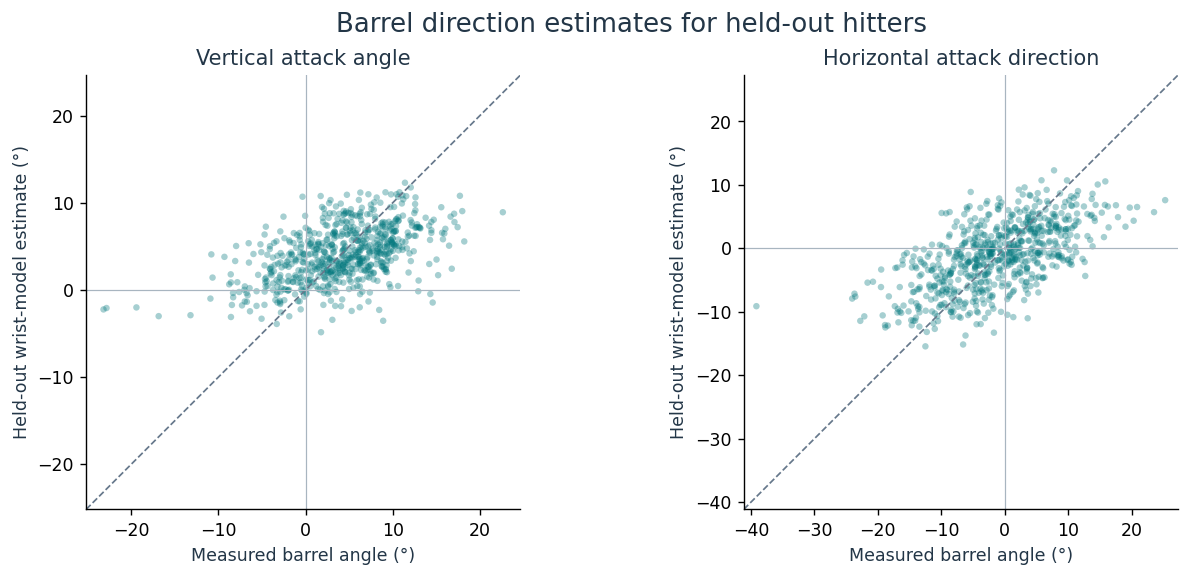

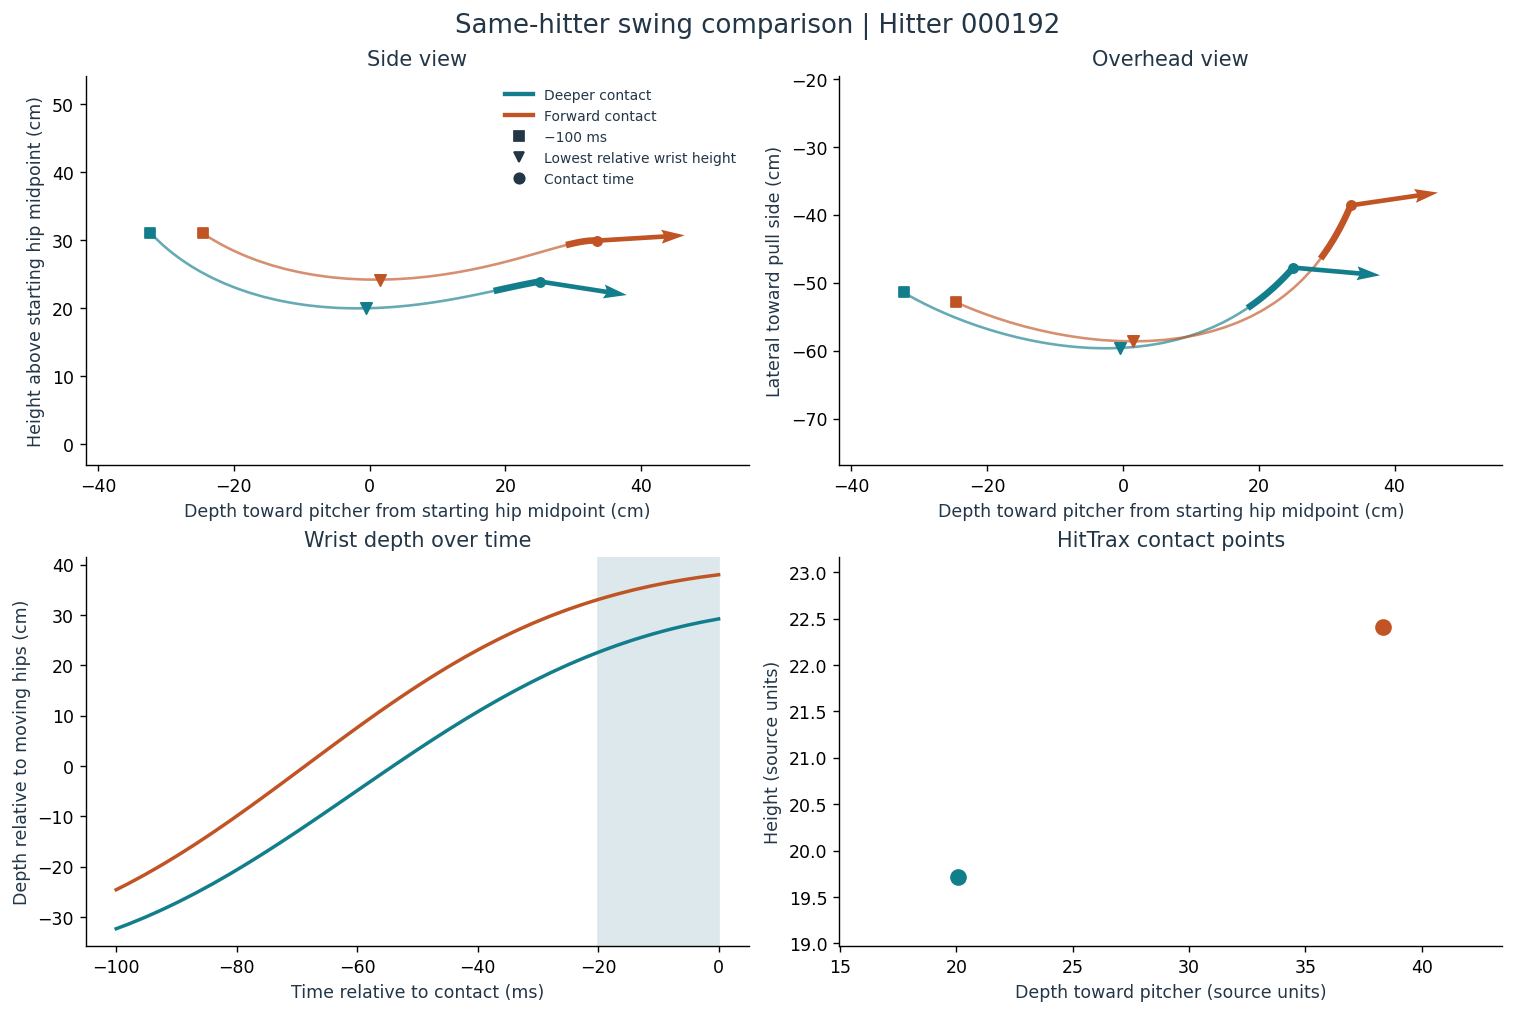

In [6]:
plt.rcParams.update({'figure.dpi': 125, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.labelcolor': '#233647', 'text.color': '#233647'})
fig_validation, axes = plt.subplots(1, 2, figsize=(10.5, 4.5), layout='constrained')
for ax, target, title in zip(axes, TARGETS, ['Vertical attack angle', 'Horizontal attack direction']):
    plot = predictions.loc[(predictions.cohort.eq('wrist cohort'))
                           & predictions.model.eq('wrist_full') & predictions.target.eq(target)]
    low = min(plot.actual_deg.min(), plot.prediction_deg.min()) - 2
    high = max(plot.actual_deg.max(), plot.prediction_deg.max()) + 2
    ax.plot([low, high], [low, high], '--', color='#66788b', lw=1)
    ax.scatter(plot.actual_deg, plot.prediction_deg, s=14, alpha=.35, color='#00777d', edgecolors='none')
    ax.axhline(0, color='#a8b5c0', lw=.7)
    ax.axvline(0, color='#a8b5c0', lw=.7)
    ax.set(xlim=(low, high), ylim=(low, high), xlabel='Measured barrel angle (°)',
           ylabel='Held-out wrist-model estimate (°)', title=title)
    ax.set_aspect('equal', adjustable='box')
fig_validation.suptitle('Barrel direction estimates for held-out hitters', fontsize=15)

def select_pair(frame):
    eligible = frame.loc[frame.impact_status.eq('valid')].dropna(
        subset=[*TARGETS, 'reported_inside', 'vertical_distance', *POI_VECTOR])
    depth_floor, depth_ceiling = eligible.impact_depth.quantile([.05, .95])
    options = []
    for _, group in eligible.groupby(PROFILE):
        if len(group) < 5:
            continue
        if PAIR_HITTER is not None and group.user.iloc[0] != str(PAIR_HITTER):
            continue
        low, high = group.impact_depth.quantile([.25, .75])
        sample = group.loc[group.impact_depth.between(depth_floor, depth_ceiling)
                           & group.reported_inside.abs().le(8.5)].sort_values(KEY)
        for one, two in combinations(sample.to_dict('records'), 2):
            deep, front = sorted([one, two], key=lambda row: row['impact_depth'])
            pitch_gap = np.hypot(front['reported_inside'] - deep['reported_inside'],
                                 front['vertical_distance'] - deep['vertical_distance'])
            depth_gap = front['impact_depth'] - deep['impact_depth']
            if pitch_gap <= 4 and depth_gap > 0 and deep['impact_depth'] <= low and front['impact_depth'] >= high:
                options.append((-depth_gap, pitch_gap, deep[KEY], front[KEY], deep, front))
    if not options:
        return pd.DataFrame()
    _, pitch_gap, _, _, deep, front = min(options, key=lambda item: item[:4])
    return pd.DataFrame([{**deep, 'swing_label': 'Deeper contact', 'reported_location_gap': pitch_gap},
                         {**front, 'swing_label': 'Forward contact', 'reported_location_gap': pitch_gap}])

pair = select_pair(primary)
fig_pair = None
if pair.empty:
    print('No pair met the location and contact-depth criteria for this selection.')
else:
    fig_pair, axes = plt.subplots(2, 2, figsize=(12, 8), layout='constrained')
    side, overhead, depth, impact = axes.flat
    colors = ['#137e8b', '#c05424']
    for (_, row), color in zip(pair.iterrows(), colors):
        t, wrist, hips = traces[row[KEY]]
        path = 100 * (wrist - hips[0])
        relative = 100 * (wrist - hips)
        low_t = row.lowest_relative_z_ms / 1000
        low_point = sample_path(t, path, [low_t])[0]
        barrel = row[POI_VECTOR].to_numpy(float)
        barrel *= 13 / np.linalg.norm(barrel)
        for ax, dim in [(side, 2), (overhead, 1)]:
            ax.plot(path[:, 0], path[:, dim], color=color, lw=1.5, alpha=.65)
            ax.plot(path[80:, 0], path[80:, dim], color=color, lw=3.8)
            ax.scatter([path[0, 0]], [path[0, dim]], marker='s', color=color, zorder=3, s=30)
            ax.scatter([low_point[0]], [low_point[dim]], marker='v', color=color, zorder=3, s=42)
            ax.scatter([path[-1, 0]], [path[-1, dim]], marker='o', color=color, zorder=4, s=28)
            ax.quiver(path[-1, 0], path[-1, dim], barrel[0], barrel[dim], angles='xy',
                      scale_units='xy', scale=1, color=color, width=.007, zorder=4)
            ax.update_datalim([path[-1, [0, dim]] + barrel[[0, dim]]])
            ax.autoscale_view()
        depth.plot(t * 1000, relative[:, 0], color=color, lw=2)
        impact.scatter(row.impact_depth, row.impact_height, color=color, s=74, label=row.swing_label)
    for ax, title, ylab in [(side, 'Side view', 'Height above starting hip midpoint (cm)'),
                            (overhead, 'Overhead view', 'Lateral toward pull side (cm)')]:
        ax.set(title=title, xlabel='Depth toward pitcher from starting hip midpoint (cm)', ylabel=ylab)
        ax.set_aspect('equal', adjustable='datalim')
        ax.margins(.12)
    depth.axvspan(-20, 0, color='#dce8ec', zorder=0)
    depth.set(title='Wrist depth over time', xlabel='Time relative to contact (ms)',
              ylabel='Depth relative to moving hips (cm)')
    impact.set(title='HitTrax contact points', xlabel='Depth toward pitcher (source units)',
               ylabel='Height (source units)')
    impact.margins(.28)
    handles = [Line2D([], [], color=color, lw=2.5, label=label)
               for label, color in zip(pair.swing_label, colors)]
    handles.extend([Line2D([], [], color='#233647', marker=marker, linestyle='none', label=label)
                    for marker, label in [('s', '−100 ms'), ('v', 'Lowest relative wrist height'),
                                          ('o', 'Contact time')]])
    side.legend(handles=handles, frameon=False, fontsize=8, loc='best')
    fig_pair.suptitle(f'Same-hitter swing comparison | Hitter {pair.user.iloc[0]}', fontsize=15)
    print(pair[['swing_label', KEY, 'reported_inside', 'vertical_distance', 'impact_depth',
                'impact_height', *EARLY, 'wrist_elevation_deg', *TARGETS]].round(2).to_string(index=False))
    print(f"Reported location gap: {pair.reported_location_gap.iloc[0]:.2f} inches")
plt.show()


In [7]:
if SAVE_OUTPUTS:
    OUT.mkdir(parents=True, exist_ok=True)
    tables = {
        'swing_features': wrist_features,
        'eligibility_audit': eligibility,
        'primary_joined_swings': primary,
        'held_out_predictions': predictions,
        'performance': performance,
        'paired_gains': gains,
        'sensitivity': sensitivity,
        'direct_wrist_agreement': direct_agreement,
        'selected_pair': pair,
    }
    for name, table in tables.items():
        table.to_csv(OUT / f'{name}.csv', index=False)
    fig_validation.savefig(OUT / 'held_out_barrel_direction.png', dpi=180)
    pair_image = OUT / 'same_hitter_pair.png'
    if fig_pair is not None:
        fig_pair.savefig(pair_image, dpi=180)
    else:
        pair_image.unlink(missing_ok=True)
    manifest = {
        'dataset': 'OpenBiomechanics Dataset v1',
        'input_sha256': {name: file_hash(RAW / name) for name in [*CSV_SOURCES, 'landmarks.csv']},
        'feature_settings_early_ms_and_hz': CONFIGS,
        'late_wrist_direction_window_ms': 20,
        'ridge_alpha': RIDGE_ALPHA,
        'bootstrap_seed': SEED,
        'bootstrap_draws': N_BOOTSTRAPS,
        'fold_by_hitter': fold_map,
    }
    (OUT / 'manifest.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')
    print('Results written to results/hand_path_barrel_direction/.')


Results written to results/hand_path_barrel_direction/.
